# Notebook 06 — Transformer Analysis

## Objectives

Analyze the internal behavior of a trained Transformer.

Topics:
1. Attention Weight Analysis
2. Attention Heatmap Visualization
3. Multi-Head Attention Analysis
4. Transformer Layer Analysis
5. Positional Encoding Analysis
6. Causal Mask Analysis

Research Process:

Prediction → Experiment → Observation → Analysis → Conclusion

In [2]:
import math
import urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", device)

PyTorch version: 2.14.1+cpu
Device: cpu


In [3]:
url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"

urllib.request.urlretrieve(url, "tinyshakespeare.txt")

with open("tinyshakespeare.txt", "r", encoding="utf-8") as file:
    text = file.read()

vocab = sorted(list(set(text)))

vocab_size = len(vocab)

char_to_id = {char: i for i, char in enumerate(vocab)}
id_to_char = {i: char for i, char in enumerate(vocab)}

data = torch.tensor(
    [char_to_id[char] for char in text],
    dtype=torch.long
)

print("Dataset size:", len(data))
print("Vocabulary size:", vocab_size)
print("Device:", device)

Dataset size: 1115394
Vocabulary size: 65
Device: cpu


In [4]:
train_size = int(0.9 * len(data))

train_data = data[:train_size]
val_data = data[train_size:]

block_size = 64
batch_size = 32

def get_batch(split):
    source = train_data if split == "train" else val_data

    ix = torch.randint(
        len(source) - block_size - 1,
        (batch_size,)
    )

    x = torch.stack([source[i:i + block_size] for i in ix])
    y = torch.stack([source[i + 1:i + block_size + 1] for i in ix])

    return x.to(device), y.to(device)

x, y = get_batch("train")

print("Train size:", len(train_data))
print("Validation size:", len(val_data))
print("Input shape:", x.shape)
print("Target shape:", y.shape)

Train size: 1003854
Validation size: 111540
Input shape: torch.Size([32, 64])
Target shape: torch.Size([32, 64])


In [5]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super().__init__()

        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(0, d_model, 2) *
            (-math.log(10000.0) / d_model)
        )

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]

In [6]:
class CausalMultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads):
        super().__init__()

        assert d_model % num_heads == 0

        self.num_heads = num_heads
        self.head_dim = d_model // num_heads

        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)

    def forward(self, x):
        B, T, C = x.shape

        Q = self.W_q(x)
        K = self.W_k(x)
        V = self.W_v(x)

        Q = Q.view(B, T, self.num_heads, self.head_dim).transpose(1, 2)
        K = K.view(B, T, self.num_heads, self.head_dim).transpose(1, 2)
        V = V.view(B, T, self.num_heads, self.head_dim).transpose(1, 2)

        scores = Q @ K.transpose(-2, -1)
        scores = scores / math.sqrt(self.head_dim)

        mask = torch.tril(torch.ones(T, T, device=x.device))
        scores = scores.masked_fill(mask == 0, float("-inf"))

        weights = F.softmax(scores, dim=-1)

        output = weights @ V
        output = output.transpose(1, 2).contiguous().view(B, T, C)
        output = self.W_o(output)

        return output, weights

In [7]:
class FeedForwardNetwork(nn.Module):
    def __init__(self, d_model, d_ff):
        super().__init__()

        self.linear1 = nn.Linear(d_model, d_ff)
        self.relu = nn.ReLU()
        self.linear2 = nn.Linear(d_ff, d_model)

    def forward(self, x):
        return self.linear2(self.relu(self.linear1(x)))


class CausalTransformerBlock(nn.Module):
    def __init__(self, d_model, num_heads, d_ff):
        super().__init__()

        self.attention = CausalMultiHeadAttention(d_model, num_heads)
        self.norm1 = nn.LayerNorm(d_model)

        self.ffn = FeedForwardNetwork(d_model, d_ff)
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, x):
        attention_output, weights = self.attention(x)
        x = self.norm1(x + attention_output)

        ffn_output = self.ffn(x)
        output = self.norm2(x + ffn_output)

        return output, weights

In [9]:
class FeedForwardNetwork(nn.Module):
    def __init__(self, d_model, d_ff):
        super().__init__()

        self.linear1 = nn.Linear(d_model, d_ff)
        self.relu = nn.ReLU()
        self.linear2 = nn.Linear(d_ff, d_model)

    def forward(self, x):
        return self.linear2(self.relu(self.linear1(x)))


class CausalTransformerBlock(nn.Module):
    def __init__(self, d_model, num_heads, d_ff):
        super().__init__()

        self.attention = CausalMultiHeadAttention(d_model, num_heads)
        self.norm1 = nn.LayerNorm(d_model)

        self.ffn = FeedForwardNetwork(d_model, d_ff)
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, x):
        attention_output, weights = self.attention(x)
        x = self.norm1(x + attention_output)

        ffn_output = self.ffn(x)
        output = self.norm2(x + ffn_output)

        return output, weights

In [10]:
class TransformerLanguageModel(nn.Module):
    def __init__(self, vocab_size, d_model, num_heads, d_ff, num_layers, max_len):
        super().__init__()

        self.embedding = nn.Embedding(vocab_size, d_model)
        self.positional_encoding = PositionalEncoding(d_model, max_len)

        self.blocks = nn.ModuleList([
            CausalTransformerBlock(d_model, num_heads, d_ff)
            for _ in range(num_layers)
        ])

        self.output_layer = nn.Linear(d_model, vocab_size)

    def forward(self, token_ids):
        x = self.embedding(token_ids)
        x = self.positional_encoding(x)

        attention_weights = []

        for block in self.blocks:
            x, weights = block(x)
            attention_weights.append(weights)

        logits = self.output_layer(x)

        return logits, attention_weights

In [11]:
torch.manual_seed(42)

model = TransformerLanguageModel(
    vocab_size=vocab_size,
    d_model=64,
    num_heads=4,
    d_ff=256,
    num_layers=2,
    max_len=block_size
).to(device)

total_params = sum(
    p.numel() for p in model.parameters()
)

x, y = get_batch("train")

with torch.no_grad():
    logits, attention_weights = model(x)

print("Total parameters:", total_params)
print("Input shape:", x.shape)
print("Output shape:", logits.shape)
print("Number of layers:", len(attention_weights))
print("Attention shape:", attention_weights[0].shape)

Total parameters: 108353
Input shape: torch.Size([32, 64])
Output shape: torch.Size([32, 64, 65])
Number of layers: 2
Attention shape: torch.Size([32, 4, 64, 64])


In [12]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001
)

max_iters = 500

for iteration in range(max_iters):
    model.train()

    x, y = get_batch("train")

    logits, _ = model(x)

    loss = F.cross_entropy(
        logits.view(-1, vocab_size),
        y.view(-1)
    )

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

    if (iteration + 1) % 100 == 0:
        print(
            f"Iteration {iteration + 1}/{max_iters} | "
            f"Loss: {loss.item():.4f}"
        )

Iteration 500/500 | Loss: 2.1348


In [14]:
@torch.no_grad()
def estimate_loss(split, eval_iters=50):
    model.eval()

    losses = []

    for _ in range(eval_iters):
        x, y = get_batch(split)
        logits, _ = model(x)

        loss = F.cross_entropy(
            logits.view(-1, vocab_size),
            y.view(-1)
        )

        losses.append(loss.item())

    return np.mean(losses)


train_loss = estimate_loss("train")
val_loss = estimate_loss("val")

print("Final Train Loss:", round(train_loss, 4))
print("Final Validation Loss:", round(val_loss, 4))
print("Generalization Gap:", round(val_loss - train_loss, 4))

Final Train Loss: 2.1521
Final Validation Loss: 2.1907
Generalization Gap: 0.0386


In [15]:
torch.save({
    "model_state_dict": model.state_dict(),
    "vocab": vocab,
    "config": {
        "vocab_size": vocab_size,
        "d_model": 64,
        "num_heads": 4,
        "d_ff": 256,
        "num_layers": 2,
        "max_len": block_size
    }
}, "transformer_analysis.pth")

print("Model checkpoint saved successfully.")

Model checkpoint saved successfully.


In [16]:
prompt = "First Citizen:"

input_ids = torch.tensor(
    [[char_to_id[c] for c in prompt]],
    dtype=torch.long
).to(device)

model.eval()

with torch.no_grad():
    logits, attention_weights = model(input_ids)

print("Input text:", prompt)
print("Input shape:", input_ids.shape)
print("Number of layers:", len(attention_weights))

for i, weights in enumerate(attention_weights):
    print(f"Layer {i + 1} attention shape:", weights.shape)

Input text: First Citizen:
Input shape: torch.Size([1, 14])
Number of layers: 2
Layer 1 attention shape: torch.Size([1, 4, 14, 14])
Layer 2 attention shape: torch.Size([1, 4, 14, 14])


In [17]:
weights = attention_weights[0][0]

print("Minimum attention:", weights.min().item())
print("Maximum attention:", weights.max().item())

print("\nSum of attention weights for each position:")
print(weights[0].sum(dim=-1))

print("\nAttention to future positions:")
print(weights[0].triu(diagonal=1))

Minimum attention: 0.0
Maximum attention: 1.0

Sum of attention weights for each position:
tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000])

Attention to future positions:
tensor([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0

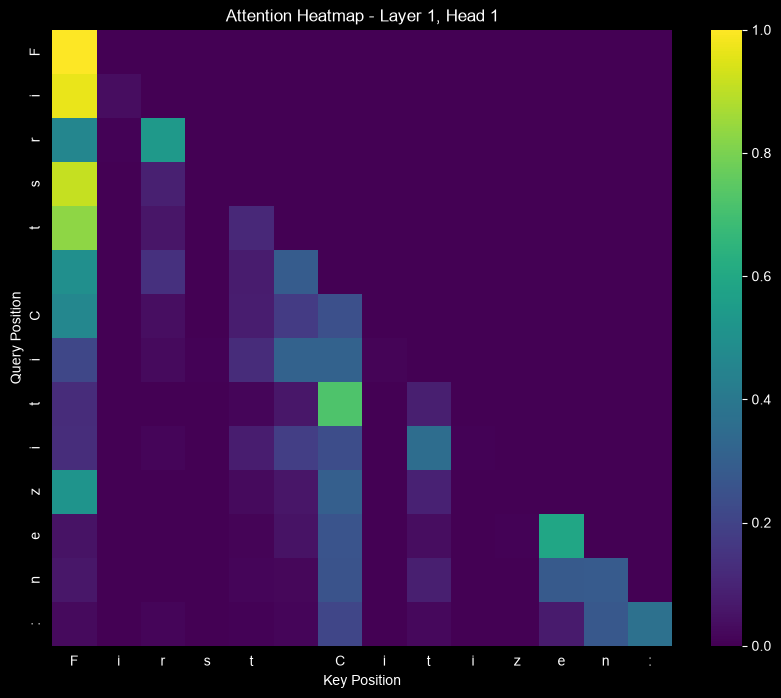

In [18]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    weights[0].cpu().numpy(),
    xticklabels=list(prompt),
    yticklabels=list(prompt),
    cmap="viridis",
    vmin=0,
    vmax=1
)

plt.xlabel("Key Position")
plt.ylabel("Query Position")
plt.title("Attention Heatmap - Layer 1, Head 1")
plt.show()

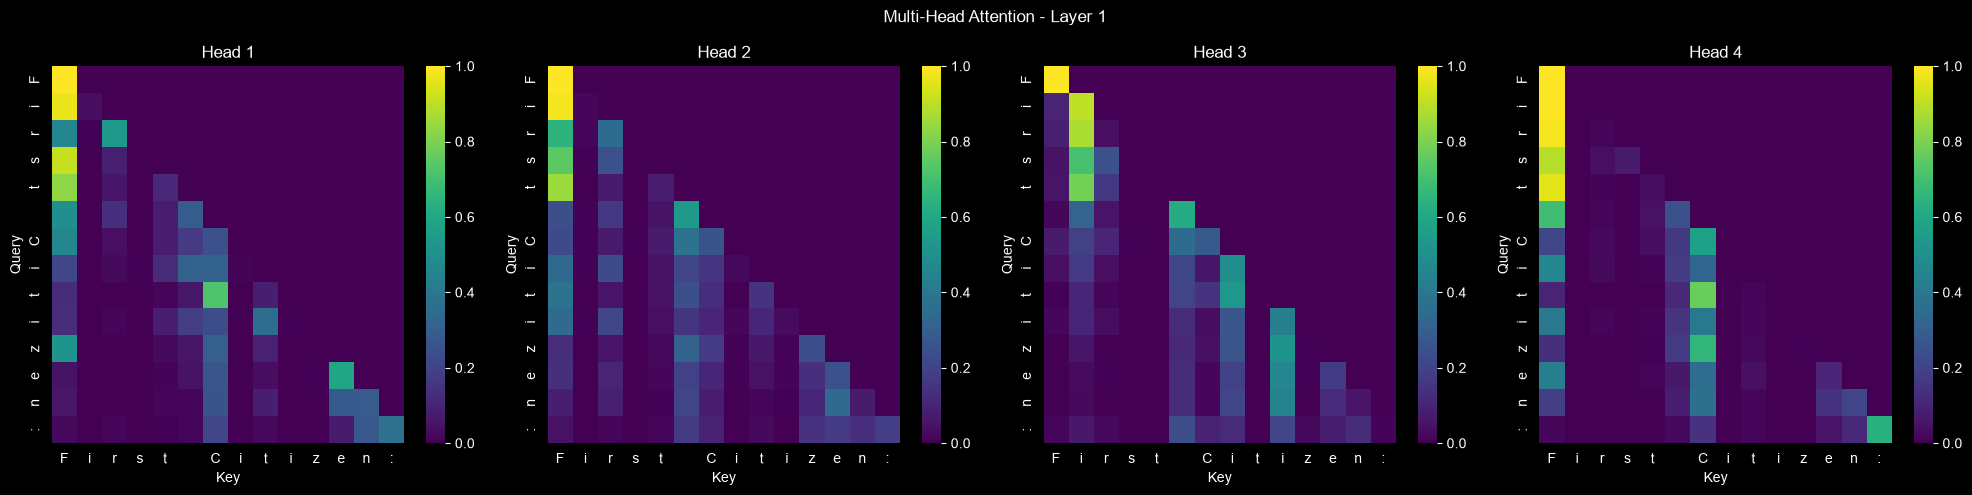

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for head in range(4):
    sns.heatmap(
        attention_weights[0][0, head].cpu().numpy(),
        ax=axes[head],
        cmap="viridis",
        vmin=0,
        vmax=1,
        xticklabels=list(prompt),
        yticklabels=list(prompt)
    )

    axes[head].set_title(f"Head {head + 1}")
    axes[head].set_xlabel("Key")
    axes[head].set_ylabel("Query")

plt.suptitle("Multi-Head Attention - Layer 1")
plt.tight_layout()
plt.show()

In [20]:
def calculate_attention_entropy(weights):
    entropy = -(
            weights * torch.log(weights + 1e-9)
    ).sum(dim=-1)

    return entropy.mean(dim=(0, 2))


for layer_index, layer_weights in enumerate(attention_weights):
    entropy = calculate_attention_entropy(layer_weights)

    print(f"\nLayer {layer_index + 1}")

    for head_index, value in enumerate(entropy):
        print(f"Head {head_index + 1}: {value.item():.4f}")


Layer 1
Head 1: 0.9908
Head 2: 1.2270
Head 3: 1.0785
Head 4: 0.7868

Layer 2
Head 1: 1.3865
Head 2: 1.5498
Head 3: 1.3484
Head 4: 1.4926


In [21]:
for layer_index, layer_weights in enumerate(attention_weights):
    print(f"\nLayer {layer_index + 1}")

    sequence_length = layer_weights.size(-1)

    positions = torch.arange(
        sequence_length,
        device=device
    )

    distances = positions[:, None] - positions[None, :]

    average_distance = (
            layer_weights * distances
    ).sum(dim=-1).mean(dim=(0, 2))

    for head_index, value in enumerate(average_distance):
        print(f"Head {head_index + 1}: {value.item():.4f}")


Layer 1
Head 1: 2.7566
Head 2: 3.1454
Head 3: 2.2155
Head 4: 3.2781

Layer 2
Head 1: 1.9730
Head 2: 2.9386
Head 3: 2.0849
Head 4: 2.2131


In [22]:
model.eval()

cutoff = 5

changed_ids = input_ids.clone()

changed_ids[:, cutoff + 1:] = (
                                      changed_ids[:, cutoff + 1:] + 1
                              ) % vocab_size

with torch.no_grad():
    original_logits, _ = model(input_ids)
    changed_logits, _ = model(changed_ids)

past_difference = (
        original_logits[:, :cutoff + 1]
        - changed_logits[:, :cutoff + 1]
).abs().max()

future_difference = (
        original_logits[:, cutoff + 1:]
        - changed_logits[:, cutoff + 1:]
).abs().max()

print("Original text:", prompt)
print(
    "Modified text:",
    "".join(id_to_char[i] for i in changed_ids[0].tolist())
)

print("Maximum difference at past positions:", past_difference.item())
print("Maximum difference at future positions:", future_difference.item())

Original text: First Citizen:
Modified text: First Djuj
fo;
Maximum difference at past positions: 0.0
Maximum difference at future positions: 7.594280242919922


In [23]:
with torch.no_grad():
    embeddings = model.embedding(input_ids)
    encoded = model.positional_encoding(embeddings)

embedding_norm = embeddings.norm(dim=-1)
encoded_norm = encoded.norm(dim=-1)

cosine_similarity = F.cosine_similarity(
    embeddings,
    encoded,
    dim=-1
)

print("Embedding shape:", embeddings.shape)
print("Encoded shape:", encoded.shape)

print("\nEmbedding norms:")
print(embedding_norm[0])

print("\nEncoded norms:")
print(encoded_norm[0])

print("\nCosine similarities:")
print(cosine_similarity[0])


Embedding shape: torch.Size([1, 14, 64])
Encoded shape: torch.Size([1, 14, 64])

Embedding norms:
tensor([8.6440, 8.1318, 7.9730, 7.8992, 7.9235, 7.0035, 8.0387, 8.1318, 7.9235,
        8.1318, 8.0504, 8.2624, 8.6117, 8.8514])

Encoded norms:
tensor([10.7757,  9.9863,  9.3510, 10.9938,  9.2709,  8.8261,  9.4412,  9.6121,
         9.7266,  9.5166, 10.1160, 10.2315, 10.7530, 10.1490])

Cosine similarities:
tensor([0.8526, 0.8241, 0.7981, 0.8709, 0.7945, 0.7680, 0.8021, 0.8093, 0.8135,
        0.8056, 0.8297, 0.8337, 0.8520, 0.8313])


In [24]:
with torch.no_grad():
    x = model.embedding(input_ids)
    x = model.positional_encoding(x)

    for layer_index, block in enumerate(model.blocks):
        previous = x.clone()

        x, _ = block(x)

        similarity = F.cosine_similarity(
            previous,
            x,
            dim=-1
        ).mean()

        mean_norm = x.norm(dim=-1).mean()

        print(f"Layer {layer_index + 1}")
        print("Mean Norm:", round(mean_norm.item(), 4))
        print("Cosine Similarity:", round(similarity.item(), 4))
        print()

Layer 1
Mean Norm: 8.2568
Cosine Similarity: 0.539

Layer 2
Mean Norm: 10.0381
Cosine Similarity: 0.6745



In [25]:
layer_entropies = []

for layer_weights in attention_weights:
    entropy = calculate_attention_entropy(layer_weights)
    layer_entropies.append(entropy.mean().item())

print("Average Attention Entropy:")

for i, value in enumerate(layer_entropies):
    print(f"Layer {i + 1}: {value:.4f}")

print(
    "\nEntropy Difference:",
    round(layer_entropies[1] - layer_entropies[0], 4)
)

Average Attention Entropy:
Layer 1: 1.0208
Layer 2: 1.4444

Entropy Difference: 0.4236


# Notebook 06 — Transformer Analysis

## 1. Attention Weight Analysis

- Attention Weights nằm trong khoảng [0, 1].
- Tổng Attention Weights trên mỗi Query Position bằng 1.
- Causal Mask đảm bảo Attention đến các vị trí tương lai bằng 0.

## 2. Multi-Head Attention Analysis

- Mỗi Transformer Layer có 4 Attention Heads.
- Các Heads tạo ra những mẫu phân bổ Attention khác nhau.
- Attention Entropy và Attention Distance giúp định lượng sự khác biệt giữa các Heads.

## 3. Layer Analysis

- Biểu diễn token thay đổi qua từng Transformer Layer.
- Cosine Similarity giữa đầu vào và đầu ra của mỗi Layer nhỏ hơn 1.
- Layer 2 có Attention Entropy trung bình cao hơn Layer 1 trong thí nghiệm.

## 4. Positional Encoding Analysis

- Positional Encoding không thay đổi kích thước Token Embedding.
- Việc cộng Positional Encoding làm thay đổi vector biểu diễn.
- Thông tin vị trí được bổ sung trước khi đi vào Transformer Blocks.

## 5. Causal Mask Experiment

- Thay đổi token tương lai không làm thay đổi logits tại các vị trí trước đó.
- Maximum Difference tại quá khứ: 0.0.
- Maximum Difference tại tương lai: 7.5943.

## 6. Conclusion

Transformer không chỉ học biểu diễn token mà còn học cách phân bổ Attention giữa các vị trí trong chuỗi.

Multi-Head Attention cung cấp nhiều cách phân bổ Attention khác nhau, trong khi các Transformer Layers tiếp tục biến đổi biểu diễn.

Causal Mask đảm bảo mô hình chỉ sử dụng thông tin hiện tại và quá khứ khi dự đoán token tiếp theo.